# Desafio do vídeo:

[Python vs Excel vs SQL vs Power BI | Which Tool Solves It Fastest?](https://www.youtube.com/watch?v=FjVSnnFEVs4&list=TLPQMjAwNjIwMjbDzXZGLvajlQ&index=3)

In [59]:
import pandas as pd
import numpy as np
spy_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/datasets/SPY_close_price_5Y.csv', parse_dates=['Date'])

## Minha solução

In [57]:
spy_df_analysis = spy_df.copy()
spy_df_analysis['Date'] = pd.to_datetime(spy_df_analysis['Date'])
spy_df_analysis.set_index('Date', inplace=True)

# Vou criar uma tolerância para dizer se os valores de Close são iguais ou não
tol = 0.5

# Criar 2 colunas, 50 day moving average, 200 day moving average, is_equal?
spy_df_analysis['50_day_moving_average'] = spy_df_analysis['Close'].rolling(window=50).mean() # Calcula a média móvel com uma janela de 50 dias
spy_df_analysis['200_day_moving_average'] = spy_df_analysis['Close'].rolling(window=200).mean()

spy_df_analysis['difference'] = np.abs((spy_df_analysis['50_day_moving_average'] - spy_df_analysis['200_day_moving_average']))
spy_df_analysis['is_equal'] = np.abs((spy_df_analysis['50_day_moving_average'] - spy_df_analysis['200_day_moving_average'])) <= tol

# Filtrar a coluna isequal com os dados que são True vai dar o dia em que as médias se encontram
spy_df_analysis[spy_df_analysis['is_equal'] == True]

,Close,50_day_moving_average,200_day_moving_average,difference,is_equal
Date,,,,,
2022-03-14,417.00,445.2328,445.62220,0.38940,True
2023-02-01,410.80,393.9354,394.35620,0.42080,True
2023-02-02,416.78,394.3504,394.25025,0.10015,True
2025-06-30,617.85,581.2730,581.72540,0.45240,True


<Axes: xlabel='Date'>

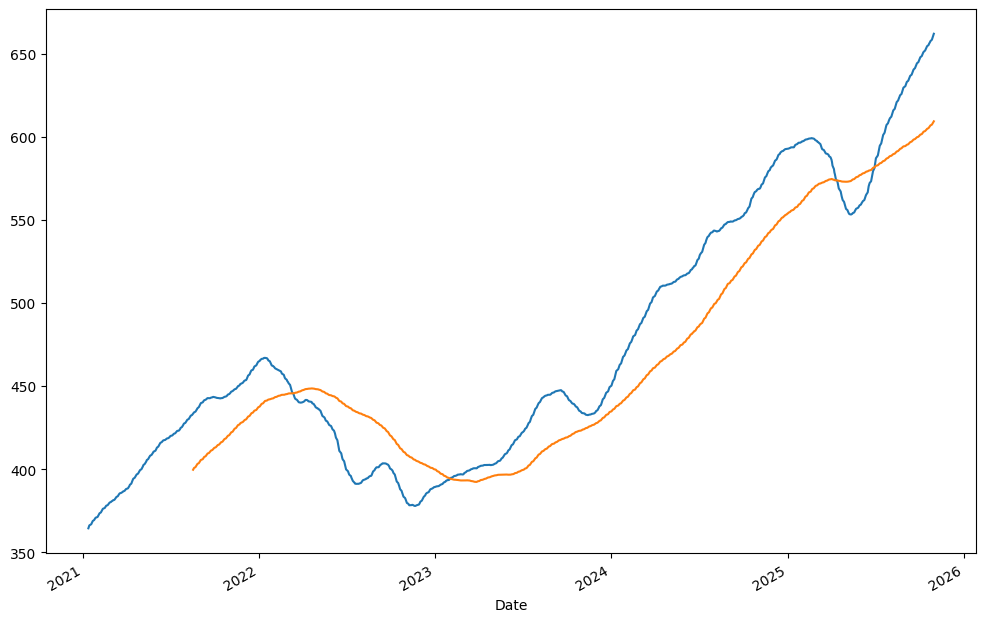

In [51]:
spy_df_analysis['50_day_moving_average'].plot(figsize=(12, 8))
spy_df_analysis['200_day_moving_average'].plot(figsize=(12, 8))
#spy_df_analysis['Close'].plot(figsize=(12, 8))


## Solução do vídeo

In [70]:
spy_df_analysis = spy_df.copy()
spy_df_analysis.assign(
    ma_50 = lambda x: x['Close'].rolling(window=50).mean(),
    ma_200 = lambda x: x['Close'].rolling(window=200).mean(),
    gc = lambda x: ((x.ma_50 > x.ma_200) & (x.ma_50.shift(1) <= x.ma_200.shift(1))).astype(int)
).query('gc==1')

,Date,Close,ma_50,ma_200,gc
566,2023-02-02,416.78,394.3504,394.25025,1
1169,2025-07-01,617.65,583.0978,582.04155,1
